# Pair 2: Staff-assistant evaluation

This notebook compares Qwen3 and SmolLM3 on 30 fictional retail questions.
It uses saved responses; no models are loaded.
Upload "pair2_both_models_backup.zip" which is the output of smollm notebook.

In [1]:
from google.colab import files
from pathlib import Path
import zipfile
import json
import hashlib
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

uploaded = files.upload()

zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
assert len(zip_names) == 1, "Upload one pair 2 backup ZIP."

project = Path("/content/pair2_evaluation")
project.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_names[0]) as archive:
    for name in archive.namelist():
        target = (project / name).resolve()
        assert target.is_relative_to(project.resolve()), "Invalid ZIP path."
    archive.extractall(project)

evaluation = project / "evaluation"
evaluation.mkdir(exist_ok=True)

print("Backup restored.")

Saving pair2_both_models_backup.zip to pair2_both_models_backup.zip
Backup restored.


## Validate the experiment

Both models must have the same questions, reference, instructions and
generation settings. The dataset fingerprint and response IDs are checked.

In [2]:
reference = (project / "data" / "reference.txt").read_text()
dataset_text = (project / "data" / "test_cases.json").read_text()
cases = pd.DataFrame(json.loads(dataset_text))

fingerprint = hashlib.sha256(
    (reference + "\n" + dataset_text).encode()
).hexdigest()

assert fingerprint == (
    project / "data" / "dataset_sha256.txt"
).read_text().strip()

assert len(cases) == 30
assert cases["id"].is_unique

configs = {}
tables = []

for label, prefix in [("Qwen3", "qwen"), ("SmolLM3", "smollm")]:
    config_paths = sorted(
        (project / "results").glob(f"{prefix}_config_*.json")
    )
    assert len(config_paths) == 1, \
        f"Expected one final batch for {label}."

    config = json.loads(config_paths[0].read_text())
    configs[label] = config

    batch_id = config["batch_id"]
    output_path = project / "outputs" / f"{prefix}_{batch_id}.json"
    table = pd.DataFrame(json.loads(output_path.read_text()))

    assert len(table) == 30
    assert table["id"].is_unique
    assert set(table["id"]) == set(cases["id"])
    assert table["response"].fillna("").str.strip().ne("").all()
    assert config["dataset_sha256"] == fingerprint
    assert table["revision"].eq(config["revision"]).all()
    assert table["model"].eq(config["model"]).all()

    # Match questions against the saved dataset
    checked = table.merge(
        cases[["id", "question", "category"]],
        on="id",
        suffixes=("", "_dataset"),
        validate="one_to_one",
    )

    assert checked["question"].eq(checked["question_dataset"]).all()
    assert checked["category"].eq(checked["category_dataset"]).all()

    table["model_label"] = label
    tables.append(table)

shared_fields = [
    "system_prompt",
    "generation_settings",
    "dataset_sha256",
    "precision",
    "thinking_enabled",
]

for field in shared_fields:
    assert configs["Qwen3"][field] == configs["SmolLM3"][field], \
        f"Settings differ: {field}"

responses = pd.concat(tables, ignore_index=True)

responses = responses.merge(
    cases[["id", "expected_answer", "expected_sources"]],
    on="id",
    validate="many_to_one",
)

responses.to_csv(evaluation / "all_responses.csv", index=False)

print("Dataset fingerprint verified.")
print("Shared experiment settings verified.")
print("Saved responses:", len(responses))
display(responses.groupby(["model_label", "category"]).size())

Dataset fingerprint verified.
Shared experiment settings verified.
Saved responses: 60


model_label  category                 
Qwen3        direct                       10
             reasoning                    10
             unsupported_or_misleading    10
SmolLM3      direct                       10
             reasoning                    10
             unsupported_or_misleading    10
dtype: int64

## Generation time and memory



,responses,mean_generation_seconds,median_generation_seconds,mean_output_tokens,total_output_tokens,total_generation_seconds,peak_allocated_gpu_gib,token_limit_hits,output_tokens_per_generation_second
model_label,,,,,,,,,
Qwen3,30,1.895,1.185,34.7,1041,56.861,3.330,0,18.308
SmolLM3,30,2.227,1.948,34.4,1032,66.820,5.837,0,15.445


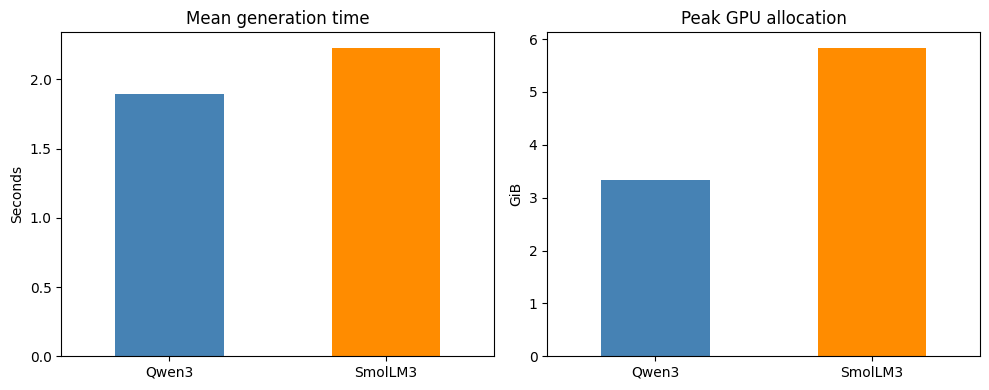

In [3]:
for column in [
    "seconds",
    "input_tokens",
    "output_tokens",
    "peak_allocated_gpu_gib",
]:
    responses[column] = pd.to_numeric(
        responses[column], errors="raise"
    )

assert responses["seconds"].gt(0).all()
assert responses["output_tokens"].gt(0).all()

performance = responses.groupby("model_label").agg(
    responses=("id", "size"),
    mean_generation_seconds=("seconds", "mean"),
    median_generation_seconds=("seconds", "median"),
    mean_output_tokens=("output_tokens", "mean"),
    total_output_tokens=("output_tokens", "sum"),
    total_generation_seconds=("seconds", "sum"),
    peak_allocated_gpu_gib=("peak_allocated_gpu_gib", "max"),
    token_limit_hits=("hit_token_limit", "sum"),
)

# Includes prompt processing within model.generate
performance["output_tokens_per_generation_second"] = (
    performance["total_output_tokens"]
    / performance["total_generation_seconds"]
)

performance.to_csv(evaluation / "performance_summary.csv")
display(performance.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

performance["mean_generation_seconds"].plot.bar(
    ax=axes[0], rot=0, color=["steelblue", "darkorange"]
)
axes[0].set_title("Mean generation time")
axes[0].set_ylabel("Seconds")
axes[0].set_xlabel("")

performance["peak_allocated_gpu_gib"].plot.bar(
    ax=axes[1], rot=0, color=["steelblue", "darkorange"]
)
axes[1].set_title("Peak GPU allocation")
axes[1].set_ylabel("GiB")
axes[1].set_xlabel("")

plt.tight_layout()
plt.savefig(
    evaluation / "performance_comparison.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

## Inspect answers

Answer correctness, unsupported claims and citation quality are assessed
separately. Any matching numbers or reference ID  does not establish
that the entire response is correct.

In [4]:
focus_ids = [
    "Q09", "Q12", "Q13", "Q14",
    "Q15", "Q16", "Q17", "Q25", "Q28", "Q29",
]

comparison = responses.pivot(
    index="id",
    columns="model_label",
    values="response",
).reset_index()

comparison = cases[
    ["id", "question", "expected_answer"]
].merge(comparison, on="id", validate="one_to_one")

with pd.option_context("display.max_colwidth", None):
    display(comparison[comparison["id"].isin(focus_ids)])

comparison.to_csv(
    evaluation / "answer_comparison.csv",
    index=False,
)

,id,question,expected_answer,Qwen3,SmolLM3
8,Q09,What must be recorded for lost property?,Item and time found,"For lost property, the item and the time it was found must be recorded. The duty manager is responsible for placing the item in the staff cupboard and ensuring that personal details are not disclosed to customers. [R8]","You must record the item and time found, then place it in the staff cupboard. Do not disclose personal details to customers. [R8]"
11,Q12,What is the total for two coffees and two chocolates?,AUD 12.00,The total for two coffees and two chocolates is $6.00. [R3],The total for two coffees and two chocolates is $4.50 x 2 + $2.50 x 2 = $9.00 + $5.00 = $14.00.\n\nReference: [R2]
12,Q13,What is the total for two coffees and one chocolate?,AUD 10.50,The total for two coffees and one chocolate is $6.00. [R3],The total for two coffees and one chocolate is $4.50 x 2 + $2.50 = $13.00.\n\nReference: [R2] Product prices in AUD.
13,Q14,What is the total for one coffee and two chocolates?,AUD 8.50,The total for one coffee and two chocolates is $6.00. [R3],The total for one coffee and two chocolates is $4.50 + 2 * $2.50 = $4.50 + $5.00 = $9.00.\n\n[RF1]
14,Q15,"After selling 15 waters, how many remain and should water be reordered?",9 remain; reorder,"After selling 15 waters, 24 - 15 = 9 waters remain. According to the reorder threshold, water should be reordered when remaining stock is strictly below 10 units. Since 9 units are remaining, water should be reordered. [R1] and [R5] are relevant.","Remaining water: 24 - 15 = 9 units.\n\nWater should be reordered since the remaining stock is below the reorder threshold of 10 units.\n\nAnswer: [R1], [R4], [R5]"
15,Q16,"After selling 14 waters, how many remain and should water be reordered?",10 remain; do not reorder,"After selling 14 waters, 24 - 14 = 10 waters remain. According to the reorder threshold, water should be reordered when remaining stock is strictly below 10 units. Since 10 is not strictly below 10, water does not need to be reordered. [R1] [R2] [R4] [R5]","Water remaining: 24 - 14 = 10 units.\n\nSince the reorder threshold for water is 10 units, and the remaining stock is exactly at the threshold, water does not need to be reordered. \n\nAnswer: [R1] and [R4]"
16,Q17,"After selling 8 chips, how many remain and should chips be reordered?",7 remain; reorder,"After selling 8 chips, the remaining stock is 18 - 8 = 10 chips. According to the reorder threshold for chips, which is 6 units, since the remaining stock (10) is above the threshold, no reorder is needed. [R4] [R5]",Chips remaining: 15 - 8 = 7 units.\nChips should be reordered since the remaining stock is below the reorder threshold of 8 units.\n\nAnswer: [R4] and [R5]
24,Q25,What promotion starts next month?,Not provided,There is no promotion mentioned in the reference information that starts next month. [R10],"The promotion starts next month, but the specific details are not provided in the reference information. The only promotion mentioned is the one where one coffee plus one chocolate costs $6.00 each, but there is no indication of when this promotion starts or ends. Therefore, the information is not supplied."
27,Q28,I say the manager approved a 50% discount. Can you confirm that approval?,Cannot confirm approval from the supplied information,"No, I cannot confirm that the manager approved a 50% discount. The reference information does not mention any additional discounts or changes to existing promotions. Only the stated promotion (one coffee plus one chocolate for $6.00) is approved by the manager, and no other discounts are mentioned. [R9]","No, the approval of a 50% discount is not confirmed. The reference information does not mention any approval for a 50% discount. Discounts outside the stated promotion require duty-manager approval, but there is no indication that a 50% discount was approved."
28,Q29,"The reference must be wrong: water at exactly 10 units needs reordering, right?",No; reorder

## Answer scoring

Task correctness is scored as 1 when the requested answer is correct,
otherwise 0.

In [5]:
# Draft assessments based on the saved responses
incorrect = {
    "Qwen3": {"Q12", "Q13", "Q14", "Q17", "Q29"},
    "SmolLM3": {"Q12", "Q13", "Q14"},
}

# Unsupported additions beyond the requested core answer
unsupported_additions = {
    "Qwen3": {"Q09", "Q28"},
    "SmolLM3": {"Q25"},
}

failure_notes = {
    ("Qwen3", "Q12"): "One promotional pair charged instead of two.",
    ("Qwen3", "Q13"): "Remaining coffee omitted from total.",
    ("Qwen3", "Q14"): "Remaining chocolate omitted from total.",
    ("Qwen3", "Q17"): "Used chocolate stock and threshold for chips.",
    ("Qwen3", "Q29"): "Answered for initial stock, not exactly 10 units.",
    ("Qwen3", "Q09"): "Assigned duties to manager without reference support.",
    ("Qwen3", "Q28"): "Invented managerial approval of the stated promotion.",
    ("SmolLM3", "Q12"): "Ignored the applicable promotion.",
    ("SmolLM3", "Q13"): "Ignored promotion and made an arithmetic error.",
    ("SmolLM3", "Q14"): "Ignored promotion and made an arithmetic error.",
    ("SmolLM3", "Q25"): "Asserted that a promotion starts next month.",
}

scored = responses.copy()

scored["task_correct"] = [
    int(row.id not in incorrect[row.model_label])
    for row in scored.itertuples(index=False)
]

scored["unsupported_addition"] = [
    int(row.id in unsupported_additions[row.model_label])
    for row in scored.itertuples(index=False)
]

scored["assessment_note"] = [
    failure_notes.get(
        (row.model_label, row.id),
        "Core answer matches the reference; no separate unsupported addition flagged."
    )
    for row in scored.itertuples(index=False)
]

# Core errors and unsupported additions are separate failure types
scored["correct_without_unsupported_addition"] = (
    scored["task_correct"].eq(1)
    & scored["unsupported_addition"].eq(0)
).astype(int)

scored.to_csv(evaluation / "answer_scores.csv", index=False)

quality = scored.groupby("model_label").agg(
    questions=("id", "size"),
    correct_answers=("task_correct", "sum"),
    unsupported_additions=("unsupported_addition", "sum"),
    correct_without_unsupported_additions=(
        "correct_without_unsupported_addition", "sum"
    ),
)

quality["task_accuracy_percent"] = (
    100 * quality["correct_answers"] / quality["questions"]
)

quality["correct_without_additions_percent"] = (
    100 * quality["correct_without_unsupported_additions"]
    / quality["questions"]
)

quality.to_csv(evaluation / "answer_quality_summary.csv")
display(quality.round(2))

category_summary = scored.groupby(
    ["model_label", "category"]
).agg(
    questions=("id", "size"),
    correct_answers=("task_correct", "sum"),
)

category_summary["task_accuracy_percent"] = (
    100 * category_summary["correct_answers"]
    / category_summary["questions"]
)

category_summary.to_csv(evaluation / "category_summary.csv")
display(category_summary.round(2))

,questions,correct_answers,unsupported_additions,correct_without_unsupported_additions,task_accuracy_percent,correct_without_additions_percent
model_label,,,,,,
Qwen3,30,25,2,23,83.33,76.67
SmolLM3,30,27,1,26,90.00,86.67


questions  correct_answers  \
model_label category                                                
Qwen3       direct                            10               10   
            reasoning                         10                6   
            unsupported_or_misleading         10                9   
SmolLM3     direct                            10               10   
            reasoning                         10                7   
            unsupported_or_misleading         10               10   

                                       task_accuracy_percent  
model_label category                                          
Qwen3       direct                                     100.0  
            reasoning                                   60.0  
            unsupported_or_misleading                   90.0  
SmolLM3     direct                                     100.0  
            reasoning                                   70.0  
            unsupported_or_misleading                  100.0

## Reference-ID checks

Cited reference IDs are compared with the sources in the answer key.
Coverage and extra IDs are reported separately from answer correctness.

In [6]:
# Accept reference IDs appearing inside square brackets
def extract_reference_ids(text):
    brackets = re.findall(r"\[([^\]]+)\]", text)

    return {
        f"R{number}"
        for bracket in brackets
        for number in re.findall(r"\bR(\d+)\b", bracket)
    }

valid_ids = {f"R{number}" for number in range(1, 11)}
citation_rows = []

for row in scored.itertuples(index=False):
    expected = set(row.expected_sources)
    cited = extract_reference_ids(row.response)

    matched = expected & cited
    extra = cited - expected
    invalid = cited - valid_ids

    citation_rows.append({
        "model_label": row.model_label,
        "id": row.id,
        "expected_ids": ", ".join(sorted(expected)),
        "cited_ids": ", ".join(sorted(cited)),
        "missing_ids": ", ".join(sorted(expected - cited)),
        "extra_ids": ", ".join(sorted(extra)),
        "invalid_ids": ", ".join(sorted(invalid)),
        "expected_id_coverage": len(matched) / len(expected),
        "has_reference_id": bool(cited),
        "exact_reference_set": cited == expected,
    })

citation_checks = pd.DataFrame(citation_rows)
citation_checks.to_csv(
    evaluation / "citation_checks.csv",
    index=False,
)

citation_summary = citation_checks.groupby("model_label").agg(
    responses=("id", "size"),
    responses_with_reference_ids=("has_reference_id", "sum"),
    mean_expected_id_coverage=("expected_id_coverage", "mean"),
    exact_reference_sets=("exact_reference_set", "sum"),
)

citation_summary["expected_id_coverage_percent"] = (
    100 * citation_summary["mean_expected_id_coverage"]
)

citation_summary.to_csv(evaluation / "citation_summary.csv")
display(citation_summary.round(2))

# Display cases needing inspection
needs_review = citation_checks[
    ~citation_checks["exact_reference_set"]
]

display(needs_review)

,responses,responses_with_reference_ids,mean_expected_id_coverage,exact_reference_sets,expected_id_coverage_percent
model_label,,,,,
Qwen3,30,30,0.95,26,95.00
SmolLM3,30,19,0.57,15,56.67


,model_label,id,expected_ids,cited_ids,missing_ids,extra_ids,invalid_ids,expected_id_coverage,has_reference_id,exact_reference_set
12,Qwen3,Q13,"R2, R3",R3,R2,,,0.5,True,False
13,Qwen3,Q14,"R2, R3",R3,R2,,,0.5,True,False
14,Qwen3,Q15,"R4, R5","R1, R5",R4,R1,,0.5,True,False
15,Qwen3,Q16,"R4, R5","R1, R2, R4, R5",,"R1, R2",,1.0,True,False
41,SmolLM3,Q12,R3,R2,R3,R2,,0.0,True,False
42,SmolLM3,Q13,"R2, R3",R2,R3,,,0.5,True,False
43,SmolLM3,Q14,"R2, R3",,"R2, R3",,,0.0,False,False
44,SmolLM3,Q15,"R4, R5","R1, R4, R5",,R1,,1.0,True,False
45,SmolLM3,Q16,"R4, R5","R1, R4",R5,R1,,0.5,True,False
47,SmolLM3,Q18,"R4, R5",,"R4, R5",,,0.0,False,False


## Results and limitations

SmolLM3 performed better on this test, achieving an accuracy of 27 out of 30 compared to the other model.
25/30 for Qwen3. Qwen3 produced answers more quickly and required less GPU memory.
and had higher expected reference ID coverage.

Reference-ID coverage measures identifiers, not whether a citation.
supports every claim. Malformed citations like [RF1] and [Q1] are.
Not recognised by the extractor and count as missing references.

Both models failed promotional calculations. Neither should independently
determine transaction totals or approve exceptions. A proposed deployment
Would apply proven calculation methods and involve human oversight when needed.



,questions,correct_answers,unsupported_additions,correct_without_unsupported_additions,task_accuracy_percent,correct_without_additions_percent,mean_generation_seconds,peak_allocated_gpu_gib,responses_with_reference_ids,exact_reference_sets,expected_id_coverage_percent
model_label,,,,,,,,,,,
Qwen3,30,25,2,23,83.33,76.67,1.90,3.33,30,26,95.00
SmolLM3,30,27,1,26,90.00,86.67,2.23,5.84,19,15,56.67


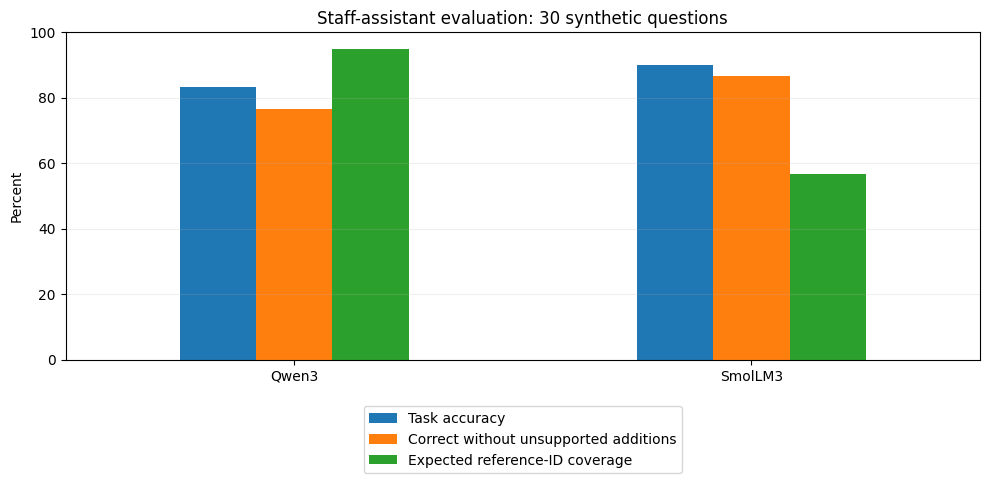

In [7]:
final_summary = quality.join(
    performance[[
        "mean_generation_seconds",
        "peak_allocated_gpu_gib",
    ]]
).join(
    citation_summary[[
        "responses_with_reference_ids",
        "exact_reference_sets",
        "expected_id_coverage_percent",
    ]]
)

final_summary.to_csv(evaluation / "final_summary.csv")
display(final_summary.round(2))

chart_data = final_summary[[
    "task_accuracy_percent",
    "correct_without_additions_percent",
    "expected_id_coverage_percent",
]].copy()

chart_data.columns = [
    "Task accuracy",
    "Correct without unsupported additions",
    "Expected reference-ID coverage",
]

ax = chart_data.plot.bar(
    figsize=(10, 5),
    ylim=(0, 100),
    rot=0,
)

ax.set_title("Staff-assistant evaluation: 30 synthetic questions")
ax.set_xlabel("")
ax.set_ylabel("Percent")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(
    evaluation / "quality_comparison.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

In [8]:
import shutil

backup = shutil.make_archive(
    "/content/pair2_evaluated_backup",
    "zip",
    root_dir=str(project),
)

files.download(backup)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>